<a href="https://colab.research.google.com/github/phuc-tran7/CMSC426/blob/project3/CMSC426_Project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

119003923*UID*:


# **CMSC426 Project 3: From Pixels to 3D Worlds : Two-View 3D Reconstruction**

# **Introduction**

We've spent a lot of time working with images, mostly in 2D scenes. Remember Project 1, where we stitched images together by finding common features between them? Well, now it’s time to take things up a notch! Imagine being able to create a 3D view of a scene using just two images and figuring out exactly where the camera was positioned relative to that scene. Sounds exciting, right?

This approach is actually a simplified version of something called Structure from Motion (SfM). While SfM usually involves reconstructing 3D structures from many images taken from different angles, we’ll start with something more manageable: Two-View Reconstruction. Instead of dealing with a whole collection of viewpoints, we’ll be focusing on building a 3D structure using only two images taken from different perspectives. The key idea? Matching features between these two images to reconstruct the scene in 3D and understand how the camera moved between shots.

* Feature Matching
* Outlier Rejection using RANSAC & Estimating the Fundamental Matrix
*  Estimating the Essential Matrix from the Fundamental Matrix
*  Estimating Camera Pose from the Essential Matrix
* Checking for Cheirality Condition using Triangulation
* Linear Triangulation of Points

Reading Module : https://cmsc733.github.io/2022/proj/p3/

Video Lecture : [link](https://drive.google.com/file/d/1KxBYehdtbVpH4A0vsNwbLpuLsGNqYH8F/view?usp=sharing)

Allowed functions: Any functions regarding reading, writing and displaying/plotting images in cv2, matplotlib

Basic math utitlies including convolution operations in numpy and math



# **Step 1: Feature Matching** [5 points]

In [1]:
# Download data from Google Drive
import gdown
gdown.download_folder(id="1ROQl0NTBnxMjLrO5qISyxcTCJUPSMsRS", quiet=True, use_cookies=False)


['/content/project3/feature_points.npz',
 '/content/project3/image1.jpg',
 '/content/project3/image2.jpg',
 '/content/project3/intrinsics.npz',
 '/content/project3/monument_reconstruction.gif']

In [2]:
def display_matches(img1, img2, pts1, pts2):
    """
    Visualize the matching points between two images.

    Input:
        img1: Image 1 in numpy array format.
        img2: Image 2 in numpy array format.
        pts1: Matched points in Image 1 (numpy array of shape Nx2).
        pts2: Matched points in Image 2 (numpy array of shape Nx2).
    """
    img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
    img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

    h1, w1 = img1_rgb.shape[:2]
    h2, w2 = img2_rgb.shape[:2]

    # Place the two images side by side on one canvas
    canvas = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
    canvas[:h1, :w1] = img1_rgb
    canvas[:h2, w1:w1 + w2] = img2_rgb

    plt.figure(figsize=(12, 8))
    plt.imshow(canvas)
    for (x1, y1), (x2, y2) in zip(pts1, pts2):
        # Shift image 2 points right by the width of image 1
        plt.plot([x1, x2 + w1], [y1, y2], 'r-', linewidth=0.7)
    plt.axis('off')
    plt.title(f'Feature Matches ({len(pts1)} correspondences)')
    plt.show()

In [3]:
def load_data(image1_path, image2_path,npz_path):
    # Load images
    img1 = cv2.imread(image1_path)
    img2 = cv2.imread(image2_path)

    # Load correspondences
    data = np.load(npz_path)
    pts1 = data['pts1']  # Nx2 array of points in the first image
    pts2 = data['pts2']  # Nx2 array of points in the second image
    return img1, img2,pts1, pts2

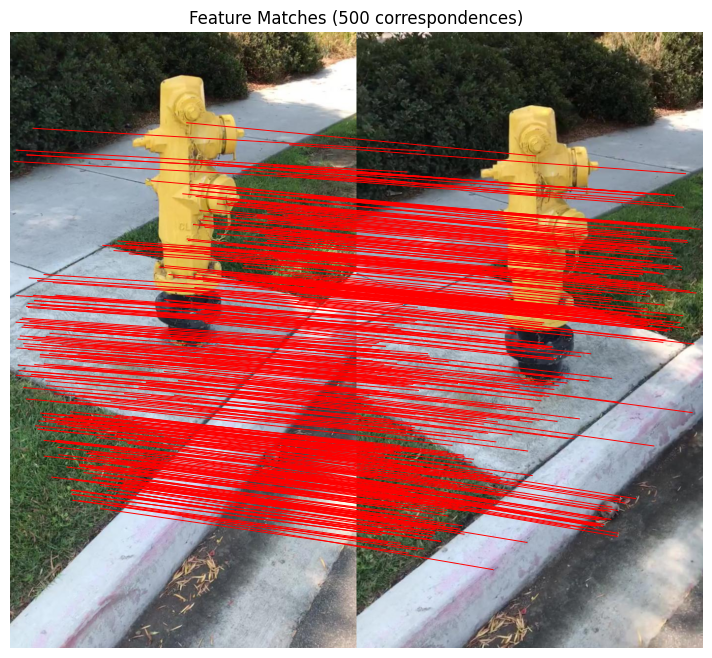

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# File paths
image1_path = '/content/project3/image1.jpg'
image2_path = '/content/project3/image2.jpg'
npz_path = '/content/project3/feature_points.npz'
intrinsics = np.load('/content/project3/intrinsics.npz')
K1 = intrinsics['K1']
K2 = intrinsics['K2']
# Load and display matches
img1, img2,pts1, pts2 = load_data(image1_path, image2_path,npz_path)

display_matches(img1, img2, pts1, pts2)

<img src = "https://drive.google.com/uc?export=view&id=1wD6L8Zl2FM75HLn8sy9ub-13ae4Jz0Hk">


# **Step 2: Fundamental Matrix Estimation and RANSAC** [15 points]
<img src="https://cmsc733.github.io/assets/2019/p3/ransac.png">

In [5]:
def estimate_Fmatrix(img1_pts, img2_pts):
  """
    Estimate the Fundamental Matrix using matched points from two images.

    Input:
        img1_pts: Matched points from Image 1 (numpy array of shape Nx2).
        img2_pts: Matched points from Image 2 (numpy array of shape Nx2).

    Output:
        F: Estimated Fundamental Matrix (3x3 numpy array).
  """
  x1, y1 = img1_pts[:, 0], img1_pts[:, 1]   # x,  y  (image 1)
  x2, y2 = img2_pts[:, 0], img2_pts[:, 1]   # x', y' (image 2)

  A = np.column_stack([x1 * x2, x1 * y2, x1,
                         y1 * x2, y1 * y2, y1,
                         x2, y2, np.ones(len(x1))])
  # Solve Af = 0: f is the last row of V^T (smallest singular value)
  _, _, Vt = np.linalg.svd(A)
  f = Vt[-1]

  F = f.reshape(3, 3).T

  U, S, Vt = np.linalg.svd(F)
  S[2] = 0
  F = U @ np.diag(S) @ Vt

  F = F / np.linalg.norm(F)
  return F



In [6]:
def ransac(pts1, pts2, iterations=1000, threshold=0.05):
  """
    Apply RANSAC to estimate the Fundamental Matrix robustly.

    Input:
        pts1: Points from Image 1 (numpy array of shape Nx2).
        pts2: Points from Image 2 (numpy array of shape Nx2).
        iterations: Number of RANSAC iterations (int).
        threshold: Distance threshold

    Output:
        img1_inliers: Inliers from Image 1 (numpy array of shape Mx2).
        img2_inliers: Inliers from Image 2 (numpy array of shape Mx2).
        best_F: Best Fundamental Matrix found (3x3 numpy array).
    """
  N = pts1.shape[0]
  pts1_h = np.hstack([pts1, np.ones((N, 1))])
  pts2_h = np.hstack([pts2, np.ones((N, 1))])

  n = 0
  best_inliers = None
  best_F = None

  for _ in range(iterations):
        # Choose 8 correspondences randomly
        idx = np.random.choice(N, 8, replace=False)
        F = estimate_Fmatrix(pts1[idx], pts2[idx])

        # Epipolar constraint residual |x2^T F x1| for every correspondence
        residuals = np.abs(np.sum(pts2_h * (F @ pts1_h.T).T, axis=1))
        S = np.where(residuals < threshold)[0]

        # Keep the F with the largest inlier set
        if n < len(S):
            n = len(S)
            best_inliers = S
            best_F = F
  img1_inliers = pts1[best_inliers]
  img2_inliers = pts2[best_inliers]

  best_F = estimate_Fmatrix(img1_inliers, img2_inliers)
  return img1_inliers, img2_inliers, best_F





In [7]:
img1_points, img2_points, F = ransac(pts1, pts2)
print("Fundamental Matrix:", F)

Fundamental Matrix: [[ 1.47653711e-07 -1.52571209e-06 -1.91925955e-03]
 [ 2.82841415e-06  5.18317586e-07 -1.47122586e-02]
 [ 1.75385561e-03  1.39747893e-02  9.99790726e-01]]


# **Draw epipolar lines** [5 points]

In [8]:
def compute_epipolar_lines_manual(pts, F):
  # Converts points to homogeneous coordinates: (x, y) -> (x, y, 1)
  pts_h = np.hstack([pts, np.ones((pts.shape[0], 1))])

  # Computes lines using F: l' = F x, each row is (a, b, c) with ax + by + c = 0
  lines = (F @ pts_h.T).T

  # Scale so that a^2 + b^2 = 1 (then |ax + by + c| is a pixel distance)
  lines = lines / np.sqrt(lines[:, 0] ** 2 + lines[:, 1] ** 2)[:, None]
  return lines
  """
    Compute epipolar lines for given points using the Fundamental Matrix.

    Input:
        pts: Points in homogeneous coordinates (numpy array of shape Nx2).
        F: Fundamental Matrix (3x3 numpy array).

    Output:
        lines: Epipolar lines in homogeneous form (Nx3 numpy array).

    Comments:
        - Converts points to homogeneous coordinates.
        - Computes lines using the Fundamental Matrix.
    """


# Function to draw epipolar lines on images
def draw_epipolar_lines_img1_points_img2_lines(img1, img2, pts1, F):
  img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
  img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
  h2, w2 = img2_rgb.shape[:2]

  # Use a random subset so the plot stays readable
  num_points = min(25, len(pts1))
  idx = np.random.choice(len(pts1), num_points, replace=False)
  sample_pts = pts1[idx]

  lines = compute_epipolar_lines_manual(sample_pts, F)

  fig, axes = plt.subplots(1, 2, figsize=(12, 8))

  # Viewpoint 1: the points only
  axes[0].imshow(img1_rgb)
  axes[0].scatter(sample_pts[:, 0], sample_pts[:, 1], c='lime', s=25)
  axes[0].set_title('Viewpoint 1 (Points Only)')
  axes[0].axis('off')

  # Viewpoint 2: the matching epipolar lines only
  axes[1].imshow(img2_rgb)
  for a, b, c in lines:
      color = np.random.rand(3)
      # Line ax + by + c = 0, evaluated at the left and right image borders
      x0, x1 = 0, w2 - 1
      y0 = -(c + a * x0) / b
      y1 = -(c + a * x1) / b
      axes[1].plot([x0, x1], [y0, y1], color=color, linewidth=1.5)
  axes[1].set_xlim(0, w2)
  axes[1].set_ylim(h2, 0)     # keep image coordinates (y points down)
  axes[1].set_title('Viewpoint 2 (Epipolar Lines Only)')
  axes[1].axis('off')

  plt.tight_layout()
  plt.show()

  """
    Draw epipolar lines on the second image for points from the first image.

    Input:
        img1: Image 1 in numpy array format.
        img2: Image 2 in numpy array format.
        pts1: Points in Image 1 (numpy array of shape Nx2).
        F: Fundamental Matrix (3x3 numpy array).

    """

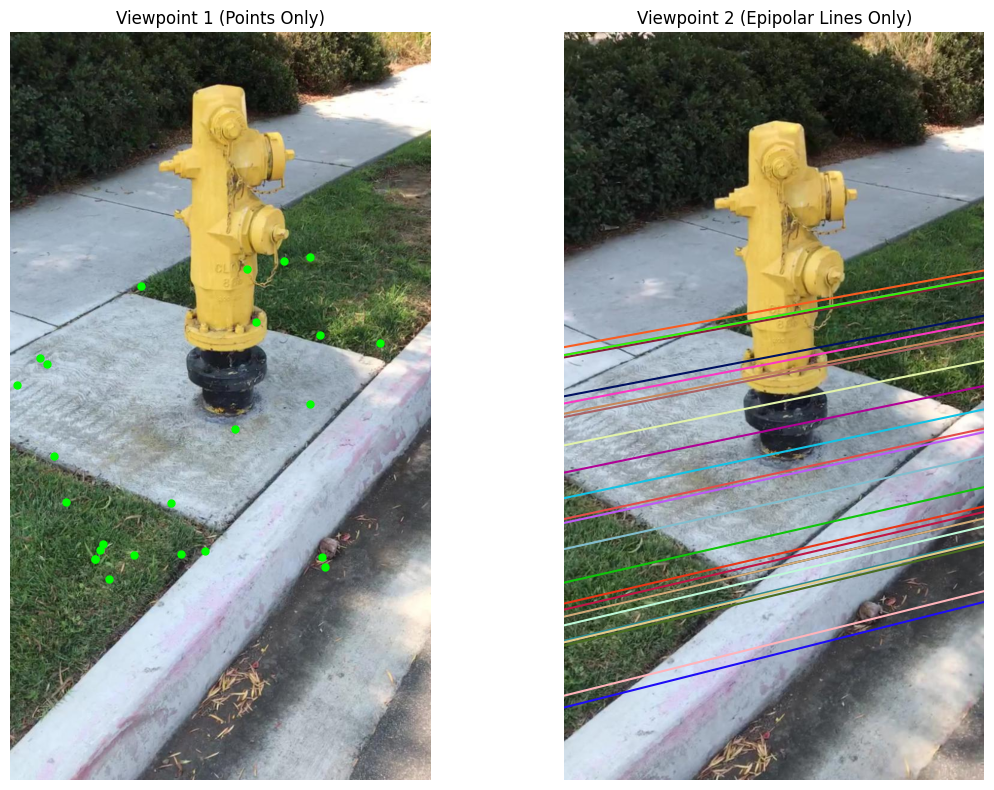

In [9]:
# Draw epipolar lines based on the fundamental matrix
draw_epipolar_lines_img1_points_img2_lines(img1, img2, img1_points, F)

<img src = "https://drive.google.com/uc?export=view&id=1iINhm8GPlx-9c3P03KPuiGuKSARqoYPD">


# **Step 3: Estimate Essential Matrix E** [15 points]



In [10]:
def estimate_Essentialmatrix(K1, K2, F):
  # E = K2^T F K1 (slide 26, two different cameras)
  E = K2.T @ F @ K1

  # Because of noise, E's singular values won't be exactly (1, 1, 0).
  # Enforce them (slide 27): E = U diag(1, 1, 0) V^T
  U, S, Vt = np.linalg.svd(E)
  E = U @ np.diag([1, 1, 0]) @ Vt
  return E

  """
    Estimate the Essential Matrix using camera intrinsics and the Fundamental Matrix.

    Input:
        K1: Intrinsic matrix of Camera 1 (3x3 numpy array).
        K2: Intrinsic matrix of Camera 2 (3x3 numpy array).
        F: Fundamental Matrix (3x3 numpy array).

    Output:
        E: Estimated Essential Matrix (3x3 numpy array).

    Comments:
        - Computes the Essential Matrix as E = K2.T * F * K
    """

In [11]:
E = estimate_Essentialmatrix(K1, K2, F)
print("Essential Matrix E:",E )

Essential Matrix E: [[ 0.01304533 -0.13161392 -0.20161304]
 [ 0.24079683  0.03367088 -0.94997829]
 [ 0.24599503  0.95668322  0.06728914]]


# **Step 4: Extracting Poses form E matrix** [20 points]
<img src = "https://drive.google.com/uc?export=view&id=1vizqzdm0gB4sRWQSrvZZPjwezW2OG5tE">




In [12]:
def get_RTset(E):
  # E = U D V^T
  U, D, Vt = np.linalg.svd(E)

  W = np.array([[0, -1, 0],
                  [1,  0, 0],
                  [0,  0, 1]])

  # The four configurations
  R = [U @ W @ Vt,      # R1 = U W V^T
        U @ W @ Vt,      # R2 = U W V^T
        U @ W.T @ Vt,    # R3 = U W^T V^T
        U @ W.T @ Vt]    # R4 = U W^T V^T

  T = [U[:, 2],         # C1 =  U(:,3)
        -U[:, 2],        # C2 = -U(:,3)
        U[:, 2],         # C3 =  U(:,3)
        -U[:, 2]]        # C4 = -U(:,3)
  for i in range(4):
        # A valid rotation needs det(R) = 1. If det(R) = -1, correct with C = -C, R = -R
        if np.linalg.det(R[i]) < 0:
            R[i] = -R[i]
            T[i] = -T[i]
        T[i] = T[i].reshape(3, 1)   # 3x1 column vector

  return R, T

  """
    Extract possible sets of rotation (R) and translation (T) from the Essential Matrix.

    Input:
        E: Essential Matrix (3x3 numpy array).

    Output:
        R: List of possible rotation matrices (4x 3x3 numpy arrays).
        T: List of possible translation vectors (4x 3x1 numpy arrays).

    Comments:
        - Uses SVD decomposition of the Essential Matrix.
        - Constructs four possible (R, T) pairs and ensures valid rotations
  """

# **Step 5: Linear Triangulation** [15 points]


In [48]:
def linear_triangulation(R_Set, T_Set, pt1, pt2, k):
    """
    Perform linear triangulation to estimate 3D points.

    Input:
        R_Set: List of possible rotation matrices (4x 3x3 numpy arrays).
        T_Set: List of possible translation vectors (4x 3x1 numpy arrays).
        pt1: Points in Image 1 (numpy array of shape Nx2).
        pt2: Points in Image 2 (numpy array of shape Nx2).
        k: Camera intrinsic matrix (3x3 numpy array).

    Output:
        points_3d_set: List of 3D points for each (R, T) pair.

    Comments:
        - Triangulates 3D points for each (R, T) pair.
    """

    #camera 1 sits at the origin with no rotation: P1 = K [I | 0]
    P1 = np.dot(k, np.hstack([np.eye(3), np.zeros((3, 1))]))

    points_3d_set = []
    for R, T in zip(R_Set, T_Set):
        #candidate camera 2: P2 = K [R | t]
        P2 = np.dot(k, np.hstack([R, T.reshape(3, 1)]))

        points_3d = []
        for (x1, y1), (x2, y2) in zip(pt1, pt2):
            # x = P X means x x (P X) = 0, which gives 2 independent equations per view:
            #   x * (p3 . X) - (p1 . X) = 0
            #   y * (p3 . X) - (p2 . X) = 0
            A = np.array([x1 * P1[2] - P1[0],
                          y1 * P1[2] - P1[1],
                          x2 * P2[2] - P2[0],
                          y2 * P2[2] - P2[1]])

            #solve A X = 0: X is the last row of V^T (smallest singular value)
            _, _, Vt = np.linalg.svd(A)
            X = Vt[-1]

            #homogeneous (X, Y, Z, W) -> Euclidean (X/W, Y/W, Z/W)
            X = X / X[3]
            points_3d.append(X[:3])

        points_3d_set.append(np.array(points_3d))

    return points_3d_set

# **Step 6: Cheriality condition** [20 points]

In [21]:
# Function to select the best pose (R, T) based on the chirality condition
def extract_pose(R_set, T_set, pts_3d_set):
    """
    Select the best pose (R, T) that satisfies the chirality condition.

    Input:
        R_set: List of possible rotation matrices (4x 3x3 numpy arrays).
        T_set: List of possible translation vectors (4x 3x1 numpy arrays).
        pts_3d_set: List of 3D point sets for each (R, T) pair.

    Output:
        R_best: Best rotation matrix (3x3 numpy array).
        T_best: Best translation vector (3x1 numpy array).
        X_best: Best 3D points (Nx3 numpy array).
        index: Index of the best (R, T) pair.

    """

    best_count = -1
    index = 0

    for i in range(len(R_set)):
        R = R_set[i]
        T = T_set[i].reshape(3, 1)
        X = pts_3d_set[i]                          # Nx3

        # Depth in camera 1: just the Z-coordinate
        depth1 = X[:, 2]

        # Depth in camera 2: transform points into camera 2's frame, take Z
        X_cam2 = np.dot(R, X.T) + T                # 3xN
        depth2 = X_cam2[2, :]

        # Count points in front of both cameras
        count = np.sum((depth1 > 0) & (depth2 > 0))
        print(f"Pose {i}: {count} / {len(X)} points in front of both cameras")

        if count > best_count:
            best_count = count
            index = i

    R_best = R_set[index]
    T_best = T_set[index].reshape(3, 1)
    X_best = pts_3d_set[index]

    return R_best, T_best, X_best, index

In [22]:
def compute_cheriality(pt, r3, t):
    """
    Compute the chirality condition to determine if points are in front of the camera.

    Input:
        pt: 3D points (Nx3 numpy array).
        r3: Third row of the rotation matrix (1x3 numpy array).
        t: Translation vector (3x1 numpy array).

    Output:
        count_depth: Number of points with positive depth.

    """

    r3 = np.asarray(r3).reshape(1, 3)
    t = np.asarray(t).reshape(3, 1)

    # Depth of every point in this camera's frame: r3 . X + t_z
    depth = np.dot(r3, pt.T).ravel() + t[2, 0]     # shape (N,)

    count_depth = np.sum(depth > 0)
    return count_depth


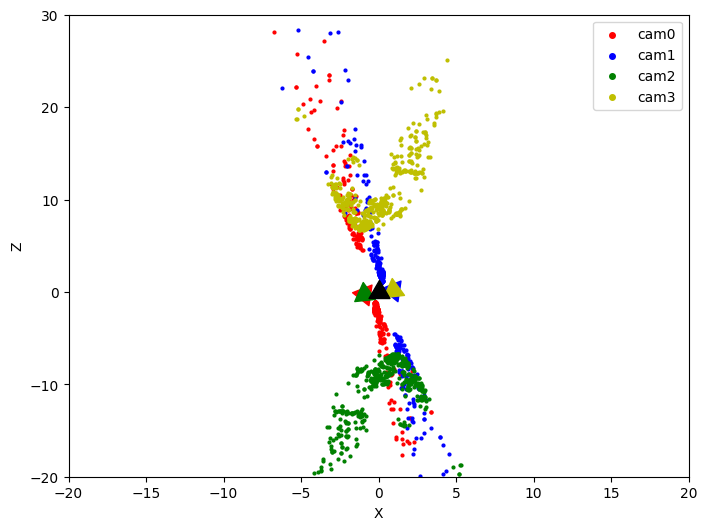

In [51]:
#_setLinear Triangulation

R_set, T_set = get_RTset(E)


point3D_set = linear_triangulation(R_set,T_set,img1_points,img2_points,K1)

#TO-DO: Plot all poses with 3D points as shown in figure

colors = ['r', 'b', 'g', 'y']

fig, ax = plt.subplots(figsize=(8, 6))

for i in range(len(R_set)):
    R = R_set[i]
    T = T_set[i].reshape(3, 1)
    X = point3D_set[i]

    # Triangulated points for this pose (X horizontal, Z = depth)
    ax.scatter(X[:, 0], X[:, 2], s=4, c=colors[i], label=f'cam{i}')

    # Camera 2 center in world coords: C = -R^T t
    C = -np.dot(R.T, T).ravel()

    # Camera 2 viewing direction (third row of R), projected onto the X-Z plane
    view_dir = R[2, :]
    angle = np.degrees(np.arctan2(view_dir[2], view_dir[0]))

    # Triangle marker rotated so its tip points the way the camera faces
    ax.scatter(C[0], C[2], marker=(3, 0, angle - 90), s=300, c=colors[i])

# Camera 1 at the origin, looking down +Z
ax.scatter(0, 0, marker=(3, 0, 0), s=300, c='k')

ax.set_xlim(-20, 20)
ax.set_ylim(-20, 30)
ax.set_xlabel('X')
ax.set_ylabel('Z')
ax.legend(markerscale=2)
plt.show()


<img src = "https://drive.google.com/uc?export=view&id=186Z0ei48e8SV-lEajldKhtilU4r_vdQI">


Pose 0: 0 / 500 points in front of both cameras
Pose 1: 0 / 500 points in front of both cameras
Pose 2: 0 / 500 points in front of both cameras
Pose 3: 500 / 500 points in front of both cameras
Selected pose: 3


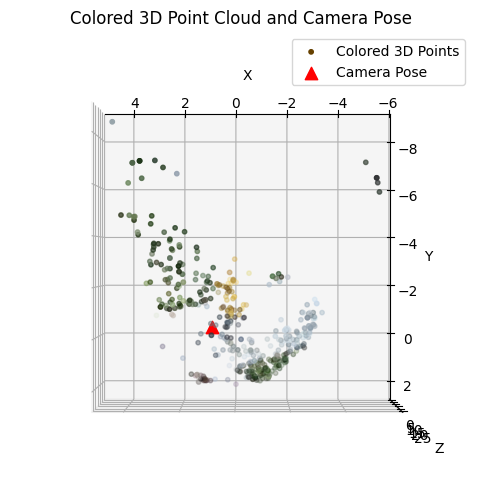

In [49]:
# Get pose of camera using chirality condition
R_best, T_best, X_, index = extract_pose(R_set, T_set, point3D_set)
print(f"Selected pose: {index}")

# TO-DO: Plot 3D point cloud with RGB color as shown in figure

# Look up each point's color from image 1 at its pixel location
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
h, w = img1_rgb.shape[:2]
u = np.clip(np.round(img1_points[:, 0]).astype(int), 0, w - 1)
v = np.clip(np.round(img1_points[:, 1]).astype(int), 0, h - 1)
point_colors = img1_rgb[v, u] / 255.0

# Camera 2 center in world coords: C = -R^T t
C = -np.dot(R_best.T, T_best.reshape(3, 1)).ravel()

# 3D plot
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_[:, 0], X_[:, 1], X_[:, 2], c=point_colors, s=10,
           label='Colored 3D Points')
ax.scatter(C[0], C[1], C[2], c='r', marker='^', s=80, label='Camera Pose')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Colored 3D Point Cloud and Camera Pose')
ax.legend()

# Look straight down the Z axis, oriented like the example
ax.view_init(elev=90, azim=90)
plt.show()

<img src = "https://drive.google.com/uc?export=view&id=1KH5L6sUD0d291MAt9OZ2zHecIinTUoXR">


# ** Reconstruct Your Own Scene! (5 Points)**

For this part, you will run an off-the-shelf incremental SfM toolbox such as [COLMAP](https://github.com/colmap/pycolmap) on your own captured multi-view images. Please submit a GIF of the reconstructed 3D structure and the location of the cameras.

For this reconstruction, you can choose your own data. This data could either be a sequence with rigid objects (e.g., a mug or a vase from your vicinity) or any scene you wish to reconstruct in 3D.


Submission:

A gif to visualize the reconstruction of the scene and location of cameras.
<img src = "https://drive.google.com/uc?export=view&id=1MmeeYX77xcQlDVzsDRWyusD8XMO2AY-m">

In [32]:
   !unzip -q photocamera.zip
   !ls photocamera

replace photocamera/DSC_0794.JPG? [y]es, [n]o, [A]ll, [N]one, [r]ename: DSC_0783.JPG  DSC_0786.JPG  DSC_0789.JPG  DSC_0792.JPG
DSC_0784.JPG  DSC_0787.JPG  DSC_0790.JPG  DSC_0793.JPG
DSC_0785.JPG  DSC_0788.JPG  DSC_0791.JPG  DSC_0794.JPG


In [33]:
!pip install pycolmap

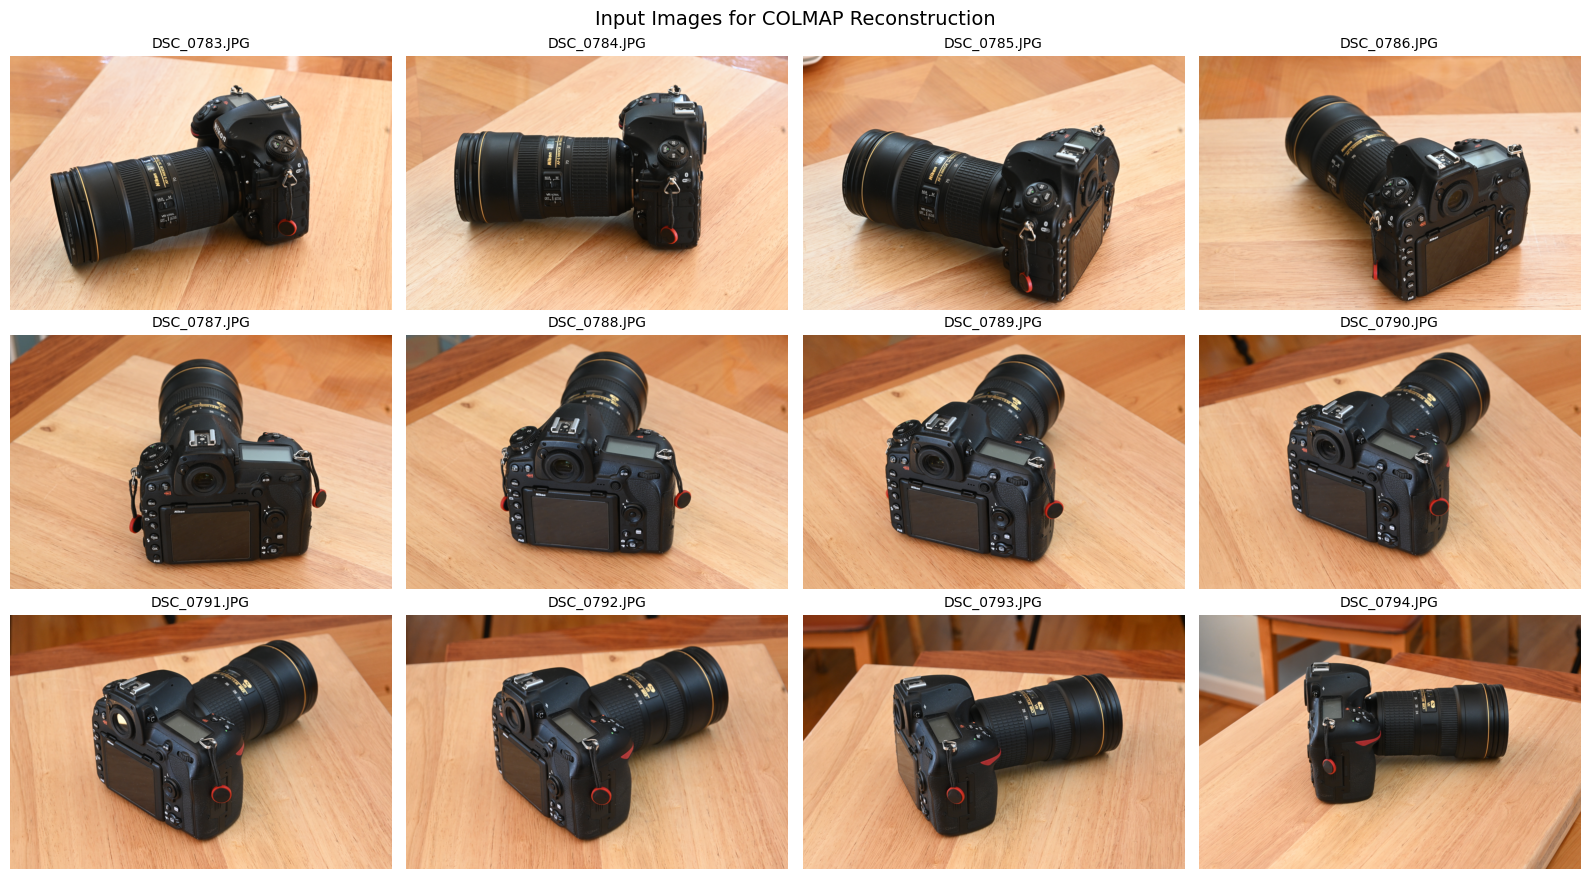

In [50]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

photos = sorted(f for f in Path('photocamera').iterdir()
                if f.suffix.lower() in ['.jpg', '.jpeg', '.png'])

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.flat, photos):
    img = Image.open(f)
    img.thumbnail((800, 800))   # shrink for faster display
    ax.imshow(img)
    ax.set_title(f.name, fontsize=10)
    ax.axis('off')

# Hide any empty slots if there are fewer than 12 photos
for ax in axes.flat[len(photos):]:
    ax.axis('off')

plt.suptitle('Input Images for COLMAP Reconstruction', fontsize=14)
plt.tight_layout()
plt.show()

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path
from PIL import Image
import pycolmap

raw_dir       = Path('photocamera')
image_dir     = Path('colmap/images')
output_dir    = Path('colmap/sparse')
database_path = Path('colmap/database.db')
image_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

# Downscale large photos for speed (keep EXIF so COLMAP can read the focal length)
for f in sorted(raw_dir.iterdir()):
    if f.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        img = Image.open(f)
        exif = img.info.get('exif', b'')
        img.thumbnail((1600, 1600))
        img.save(image_dir / f.name, quality=95, exif=exif)

# COLMAP pipeline: features -> matching -> incremental SfM
if database_path.exists():
    database_path.unlink()
pycolmap.extract_features(database_path, image_dir,
                          camera_mode=pycolmap.CameraMode.SINGLE)
pycolmap.match_exhaustive(database_path)
maps = pycolmap.incremental_mapping(database_path, image_dir, output_dir)

# Use the largest reconstruction
rec = max(maps.values(), key=lambda r: r.num_reg_images())
print(rec.summary())

Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 12
	num_reg_frames = 12
	num_images = 12
	num_points3D = 1947
	num_observations = 7208
	mean_track_length = 3.70211
	mean_observations_per_image = 600.667
	mean_reprojection_error = 0.348008


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

USE_RGB = True   # True = real photo colors, False = all red like the example

# ---- 3D points ----
xyz = np.array([p.xyz for p in rec.points3D.values()])
rgb = np.array([p.color for p in rec.points3D.values()]) / 255.0

# Trim far-off outlier points so the object fills the frame
lo, hi = np.percentile(xyz, 2, axis=0), np.percentile(xyz, 98, axis=0)
keep = np.all((xyz >= lo) & (xyz <= hi), axis=1)
xyz, rgb = xyz[keep], rgb[keep]

# ---- camera poses (world -> camera: x_cam = R x_world + t) ----
def get_Rt(image):
    T = image.cam_from_world() if callable(image.cam_from_world) else image.cam_from_world
    R = T.rotation.matrix() if hasattr(T.rotation, 'matrix') else np.array(T.rotation)
    return np.array(R), np.array(T.translation)

images = sorted(rec.images.values(), key=lambda im: im.name)
poses = [get_Rt(im) for im in images]
centers = np.array([-R.T @ t for R, t in poses])   # camera centers in world coords

# ---- Make the scene upright ----
# Each camera's "up" in world coords is -(its y-axis) = -R[1, :]
up = -np.mean([R[1, :] for R, t in poses], axis=0)
up /= np.linalg.norm(up)

# Rotation A that maps 'up' onto +Z (Rodrigues formula)
z = np.array([0.0, 0.0, 1.0])
v = np.cross(up, z)
c = np.dot(up, z)
if np.linalg.norm(v) < 1e-8:
    A = np.eye(3) if c > 0 else np.diag([1, -1, -1])
else:
    vx = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
    A = np.eye(3) + vx + vx @ vx * (1 / (1 + c))

# Apply A to the points, the camera centers, and the camera poses
xyz = (A @ xyz.T).T
centers = (A @ centers.T).T
poses = [(R @ A.T, t) for R, t in poses]   # x_cam = R A^T (A x) + t

# ---- Center the rotation on the object and zoom in ----
mid = xyz.mean(axis=0)
r = np.linalg.norm(centers - mid, axis=1).max() * 0.75   # raise to 0.85-0.9 if cameras get cut off
s = 0.04 * r                                             # frustum size

def frustum_faces(R, t, s):
    # Pyramid in camera coords: apex at the camera center, base in front of it (+Z)
    corners_cam = np.array([[-1, -0.75, 1.5], [1, -0.75, 1.5],
                            [1,  0.75, 1.5], [-1,  0.75, 1.5]]) * s
    C = -R.T @ t
    base = (R.T @ corners_cam.T).T + C              # camera -> world
    sides = [[C, base[i], base[(i + 1) % 4]] for i in range(4)]
    return sides + [list(base)]

# ---- plot ----
fig = plt.figure(figsize=(8, 6), facecolor='black')
ax = fig.add_subplot(111, projection='3d', facecolor='black')

ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2],
           c=(rgb if USE_RGB else 'red'), s=4, depthshade=False)

for R, t in poses:
    ax.add_collection3d(Poly3DCollection(frustum_faces(R, t, s),
                                         facecolors='red', edgecolors='darkred',
                                         linewidths=0.5, alpha=0.9))

ax.set_xlim(mid[0] - r, mid[0] + r)
ax.set_ylim(mid[1] - r, mid[1] + r)
ax.set_zlim(mid[2] - r, mid[2] + r)
ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()                                   # no axes, grid, or panes
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

def update(angle):
    ax.view_init(elev=25, azim=angle)               # look down slightly at the table
    return ()

anim = FuncAnimation(fig, update, frames=range(0, 360, 3), interval=50)
anim.save('reconstruction.gif', writer=PillowWriter(fps=20),
          savefig_kwargs={'facecolor': 'black'})
plt.close(fig)
print("Saved reconstruction.gif")

Saved reconstruction.gif


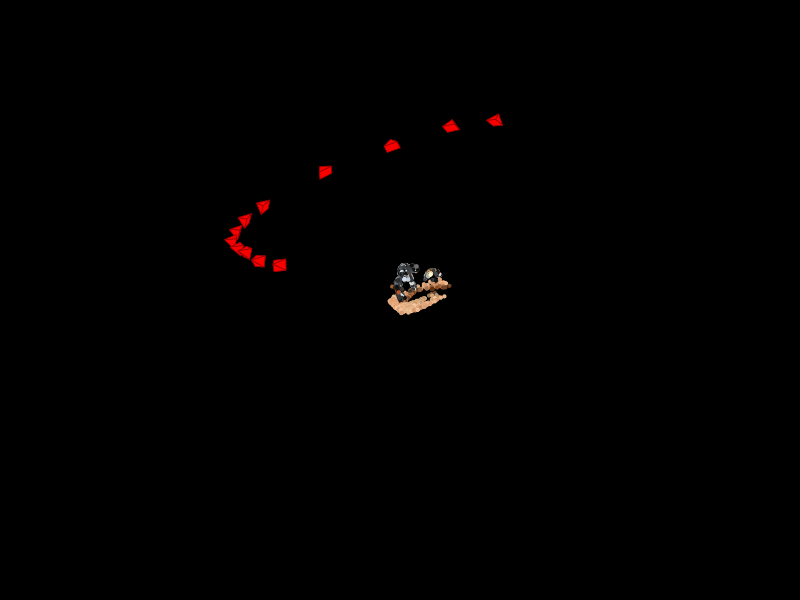

In [47]:
from IPython.display import Image as IPImage
IPImage(filename='reconstruction.gif')

## Report
You will be graded primarily based on your report.
A demonstration of understanding of the concepts involved in the project are required show the output produced by your code.

Include visualizations of the output of each stage in your pipeline (as shown in the system diagram on page 2), and a description of what you did for each step. Assume that we’re familiar with the project, so you don’t need to spend time repeating what’s already in the course notes. Instead, focus on any interesting problems you encountered and/or solutions you implemented.

# Submission Guidelines

**If your submission does not comply with the following guidelines, you’ll be given ZERO credit.**

Your submission on ELMS(Canvas) must be a pdf file, following the naming convention **YourDirectoryID_proj3.pdf**. For example, xyz123_proj3.pdf.

**All your results and report should be included in this notebook. After you finished all, please export the notebook as a pdf file and submit it to ELMS(Canvas).**

# Collaboration Policy
You are encouraged to discuss the ideas with your peers. However, the code should be your own, and should be the result of you exercising your own understanding of it. If you reference anyone else’s code in writing your project, you must properly cite it in your code (in comments) and your writeup. For the full honor code refer to the CMSC426 Fall 2023 website.

Project Inspiration Credit to CMSC733 COmputer Vision and 16-822: Geometry-based Methods in Vision
